# Automated ML Pipeline

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

## Config code 
 

In [ ]:
FILE_PATH = "../Data/Pipeline_data/Regression/insurance/insurance.csv"

if "_target_cache" not in globals():
    _target_cache = {'path': None, 'target': None, 'task': None}

def load_data(file_path):
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
    return pd.read_csv(file_path)

def ask_target(df):
    print("Columns:",list(df.columns))
    while True:
        target = input("Enter the target column").strip()
        if target in df.columns:
            return target
        print(f"'{target}' not found. Try again.")

def get_target(df, file_path):
    if _target_cache['path'] == file_path and _target_cache['target'] in df.columns:
        print(f"Same file, reusing target: {_target_cache['target']}")
        return _target_cache['target']
    target = ask_target(df)
    _target_cache.update({'path': file_path, 'target': target, 'task': None})
    return  target

df = load_data(FILE_PATH)
TARGET = get_target(df, FILE_PATH)

Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


## Inspection 

In [3]:
def inspection(df):
    # checking the shape of data 
    print(f"rows: {df.shape[0]} \ncolumns: {df.shape[1]}\n")

    # checking for numerical and string columns
    num_col = df.select_dtypes(include='number').columns.tolist()
    string_col = df.select_dtypes(include=['object', 'string']).columns.tolist()
    print(f'Numerical Columns: {num_col} \nString Columns: {string_col}\n')

    # missing value percentage
    percentage = (df.isna().mean() * 100).round(3).to_dict()
    null_pct = {col: pct for col, pct in percentage.items() if pct > 0}
    if not null_pct:
        print("Null Values: 0%\n")
    else:
        for col, pct in null_pct.items():
            print(f"{col}: {pct}%\n")

    # Unique Value count per column
    unique_val = df[string_col].nunique().to_dict()
    for col, val in unique_val.items():
        print(f"{col} unique values: {val}") # \n here add new line after execution of for loop every time
    print('') # adds an empty line \n not used because it add 2 empty rows 
  
    # duplicate rows
    print(f"Duplicate rows: {df.duplicated().sum()}\n")

    # constant columns
    constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
    print(f"Constant columns: {constant_cols if constant_cols else 'None'}")

inspection(df)

rows: 1338 
columns: 7

Numerical Columns: ['age', 'bmi', 'children', 'charges'] 
String Columns: ['sex', 'smoker', 'region']

Null Values: 0%

sex unique values: 2
smoker unique values: 2
region unique values: 4

Duplicate rows: 1

Constant columns: None


Target 'charges' is numeric (float64)

count : 1338.0
mean : 13270.422
std : 12110.011
min : 1121.874
25% : 4740.287
50% : 9382.033
75% : 16639.913
max : 63770.428

Skewness of 'charges': 1.516 (strongly skewed)


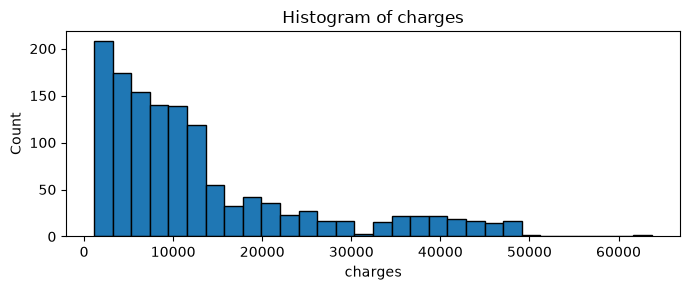

In [4]:
def target_check(df, target):
    # data type
    # this prints the data type of the target 
    kind = df[target].dtype.kind 
    if kind in 'iuf':
        print(f"Target '{target}' is numeric ({df[target].dtype})\n")
    elif kind in 'OU':
        print(f"Target '{target}' is string ({df[target].dtype})\n")
    else:
        print(f"Target '{target}' is non numeric ({df[target].dtype})\n")

    # describe the target 
    # this code store the values of describing the target to a dict with round value upto 3 
    if kind in 'iuf':
        desc_data = df[target].describe().round(3).to_dict()
        for desc, val in desc_data.items():
            print(f"{desc} : {val}")
        print('') # this only add an empty line 

    # first check if the target is numeric or not and the unique values
    if kind in 'iuf' and df[target].nunique() > 10:
        # skewness
        # this calculate the skewness of the target and tells if the target is how much skewed 
        skewness = df[target].skew()
        if abs(skewness) <=0.5:
            label = 'roughly symmetric'
        elif abs(skewness) <=1:
            label = 'moderately skewed'
        else:
            label = 'strongly skewed'
        print(f"Skewness of '{target}': {skewness:.3f} ({label})")

    # first check for numeric values
    if kind in 'iuf':
        fig, axes = plt.subplots(figsize=(7, 3))
        axes.hist(df[target].dropna(), bins=30, edgecolor='black')
        axes.set_title(f"Histogram of {target}")
        axes.set_xlabel(target)
        axes.set_ylabel("Count")
        plt.tight_layout()
        plt.show()
    else:
        print("Skipping plots: target is not numeric")
    

target_check(df, TARGET)

In [ ]:
def confirm(message):
        return input(f"{message} Continue? (y/n):").strip().lower() == 'y'

def get_task_type(df, target, warn_unique):
        if _target_cache['task'] is not None:
                print(f"Same file and target, reusing task type: {_target_cache['task']}")
                return _target_cache['task']
        series = df[target]
        is_numeric = series.dtypes.kind in 'iuf'
        n_unique = series.nunique()

        